# AISE 4010 Project - Group 2

Abdullayev, Jahangir

Heddle, Bryan William

Linders, Matthew Donald

Renno, Nimer

In [6]:
# Install missing packages in the current notebook kernel's environment.
import importlib.util
import subprocess
import sys

# TODO: remove any unused packages from the list below at end
packages = ["pandas", "matplotlib", "seaborn", "plotly", "statsmodels"]
missing = [package for package in packages if importlib.util.find_spec(package) is None]

if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])
else:
    print("All required packages are already installed.")

# Stage 1 — Data, baselines, MLP

In [7]:
# Import dataset
import pandas as pd

dataset_url = "https://raw.githubusercontent.com/laiguokun/multivariate-time-series-data/master/traffic/traffic.txt.gz"
# Download into memory and decompress directly; no local dataset file is needed.
df = pd.read_csv(dataset_url, compression="gzip", header=None)

print(f"Loaded {df.shape[0]:,} time steps and {df.shape[1]:,} traffic sensors.")
df.head()

Loaded 17,544 time steps and 862 traffic sensors.


,0,1,2,3,4,5,6,7,8,9,...,852,853,854,855,856,857,858,859,860,861
0,0.0048,0.0146,0.0289,0.0142,0.0064,0.0232,0.0162,0.0242,0.0341,0.0375,...,0.0051,0.0051,0.0074,0.0079,0.0051,0.0051,0.0339,0.0051,0.0100,0.0121
1,0.0072,0.0148,0.0350,0.0174,0.0084,0.0240,0.0201,0.0338,0.0434,0.0381,...,0.0036,0.0036,0.0107,0.0058,0.0036,0.0036,0.0348,0.0036,0.0087,0.0136
2,0.0040,0.0101,0.0267,0.0124,0.0049,0.0170,0.0127,0.0255,0.0332,0.0309,...,0.0030,0.0030,0.0043,0.0050,0.0030,0.0030,0.0327,0.0030,0.0061,0.0107
3,0.0039,0.0060,0.0218,0.0090,0.0029,0.0118,0.0088,0.0163,0.0211,0.0199,...,0.0033,0.0033,0.0019,0.0052,0.0033,0.0033,0.0292,0.0033,0.0040,0.0071
4,0.0042,0.0055,0.0191,0.0082,0.0024,0.0095,0.0064,0.0087,0.0144,0.0226,...,0.0049,0.0049,0.0011,0.0071,0.0049,0.0049,0.0264,0.0049,0.0040,0.0039


## Understanding the Dataset

This dataset records **hourly road occupancy at 862 traffic sensors on San Francisco Bay Area freeways**. Occupancy measures the fraction of time a sensor detects a vehicle: `0.05` means 5% occupancy, rather than a vehicle count or speed.

Each **row** represents one hourly observation, ordered through time. Each **column**, numbered `0`–`861`, represents a different sensor. The dataset contains **17,544 observations**. This file does not include timestamps, sensor names, or locations, so its row and column numbers are positional identifiers.

[Dataset source and description](https://github.com/laiguokun/multivariate-time-series-data#traffic-usage)

In [8]:
import matplotlib.pyplot as plt

df.info()
print("Missing values:", df.isna().sum().sum())
display(df.iloc[:, :5].describe())


<class 'pandas.DataFrame'>
RangeIndex: 17544 entries, 0 to 17543
Columns: 862 entries, 0 to 861
dtypes: float64(862)
memory usage: 115.4 MB
Missing values: 0


,0,1,2,3,4
count,17544.000000,17544.000000,17544.000000,17544.000000,17544.000000
mean,0.049324,0.046016,0.105870,0.056633,0.026812
std,0.062469,0.048398,0.082205,0.036746,0.035872
min,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.008900,0.018100,0.035600,0.026800,0.007875
50%,0.046300,0.036800,0.081000,0.060000,0.019000
75%,0.059900,0.053700,0.175500,0.074700,0.024300
max,0.474700,0.450000,0.420100,0.494700,0.406900


## Forecasting Target

For Stage 1, we will use the **previous 24 hourly observations from sensor column `0` to predict its road occupancy one hour ahead**. We repeat this one-step forecast as new observations become available.

- **Target:** the next hourly occupancy value in column `0`.
- **Unit:** occupancy fraction from 0 to 1; `0.05` means 5% occupancy.
- **Inputs (lookback):** the previous 24 hourly observations from the same sensor.
- **Forecast horizon:** one hourly time step ahead.

The baseline, MLP, and CNN will use the same historical inputs and predict the same target observations for a fair comparison. Column `0` is a fixed choice made before modelling, rather than a sensor selected based on prediction results. Its physical location is not provided in this file.

**Limitation:** results for this one sensor may not generalize to the other 861 sensors.


## Data Audit and Preprocessing Rules

We keep the source matrix unchanged in `df` and use column `0` as our target. The source describes hourly occupancy fractions. We keep that native hourly frequency: **no aggregation, downsampling, or interpolation onto new timestamps** is needed.

**Coverage:** this file contains 17,544 ordered hourly records (731 days of nominal hourly samples). That is a sample-count duration, not verified calendar coverage. The file contains no dates, so exact start/end timestamps, timezone, timestamp gaps, and duplicate timestamps **cannot be verified**. We preserve the source order and explicitly assume each adjacent row represents the next hour.

**Duplicates:** count repeated full measurement rows, but keep them. Equal sensor readings at different hours can be valid; deleting them would change the sequence and its lag spacing. Row-index uniqueness is checked separately and does not prove timestamp uniqueness.

**Missing values:** report missingness before cleaning. Use causal forward fill for missing target inputs, carrying only the latest past observation forward. Never backward-fill or interpolate using future values. Preserve an observed-target mask so future validation/test metrics exclude imputed targets. Leading missing values cannot be forward-filled and trigger a clear error. No scaler is fitted in this section; it must be fitted on the training split later.


In [9]:
import numpy as np

TARGET_COLUMN = 0
NATIVE_FREQUENCY_HOURS = 1
MODEL_FREQUENCY_HOURS = 1

series_raw = df[TARGET_COLUMN].copy()
series_raw.name = "occupancy_sensor_0"
target_observed = series_raw.notna()

values = df.to_numpy()
audit = pd.Series({
    "Rows (hourly records)": len(df),
    "Sensor columns": df.shape[1],
    "Nominal duration in days (rows / 24)": len(df) / 24,
    "Missing cells (all sensors)": int(df.isna().sum().sum()),
    "Missing target values": int(series_raw.isna().sum()),
    "Repeated full rows beyond first occurrence (retained)": int(df.duplicated().sum()),
    "Repeated row-index labels": int(df.index.duplicated().sum()),
    "Infinite values (all sensors)": int(np.isinf(values).sum()),
    "Values outside [0, 1] (all sensors)": int(((values < 0) | (values > 1)).sum()),
    "Exact calendar coverage": "Unavailable: no timestamps supplied",
    "Timestamp gaps / duplicate timestamps": "Cannot verify from this matrix",
}, name="Audit result")
display(audit.to_frame())

# Resampling rule: retain the native hourly observations unchanged.
# Do not invent a datetime index to call resample() on this timestamp-free file.
assert MODEL_FREQUENCY_HOURS == NATIVE_FREQUENCY_HOURS
series_hourly = series_raw.copy()
pd.testing.assert_series_equal(series_hourly, series_raw)
print("Resampling: none; native hourly observations retained.")

# Repeated measurement rows are intentionally retained, preserving every time step.
assert df.index.is_unique and df.index.is_monotonic_increasing
if (np.isinf(series_raw.to_numpy()) | (series_raw < 0) | (series_raw > 1)).any():
    raise ValueError("Target contains infinite or out-of-range occupancy values; investigate before modelling.")

# Causal input cleaning only: never use these filled values as evaluation ground truth.
series = series_hourly.ffill() # Forward-fill missing values, retaining the first valid value for each leading NaN.
if series.isna().any():
    raise ValueError("Leading target values are missing and have no past value for forward fill.")
print(f"Target values forward-filled: {int(series_raw.isna().sum()):,}")
print(f"Missing target values remaining: {int(series.isna().sum()):,}")
print("Observed-target mask retained in target_observed for later evaluation.")


,Audit result
Rows (hourly records),17544
Sensor columns,862
Nominal duration in days (rows / 24),731.0
Missing cells (all sensors),0
Missing target values,0
Repeated full rows beyond first occurrence (retained),14
Repeated row-index labels,0
Infinite values (all sensors),0
"Values outside [0, 1] (all sensors)",0
Exact calendar coverage,Unavailable: no timestamps supplied


Resampling: none; native hourly observations retained.
Target values forward-filled: 0
Missing target values remaining: 0
Observed-target mask retained in target_observed for later evaluation.


### Audit Findings

The loaded file has **no missing values, infinite values, or values outside the occupancy range [0, 1]**. Forward fill therefore changes no target values. The audit finds **14 repeated full measurement rows beyond their first occurrence**. These are retained because identical observations do not establish duplicate timestamps. No temporal rows are deleted, and the hourly data are not resampled.

Calendar coverage and timestamp gaps remain unverified because the source matrix does not contain timestamps. This is a documented data limitation, rather than evidence that no gaps exist.


## Exploratory Figures

These plots describe the selected target before modelling. The first two use the initial 60% of rows, matching the planned training period, so model-development choices do not depend on held-out patterns. Plot original observations so missing measurements, if present, remain visible. Horizontal coordinates are observation positions, not verified calendar dates.

- **Occupancy history:** long-term behavior and a trailing 24-observation mean, to reveal changes in occupancy level.
- **Weekly detail:** a closer view of the first 168 observations, to inspect short-term peaks and repeated patterns.
- **Autocorrelation:** training-period autocorrelation through lag 168, to inspect dependence at hourly, daily, and weekly sample spacings under the hourly-row assumption.


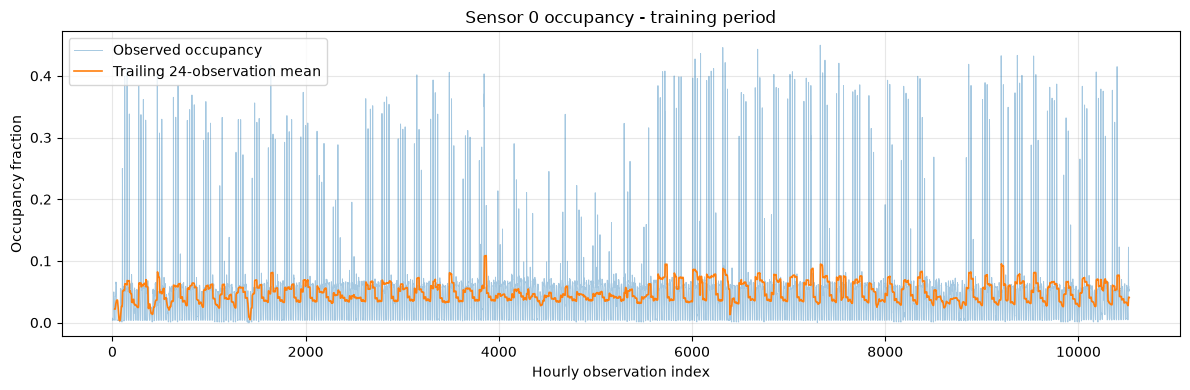

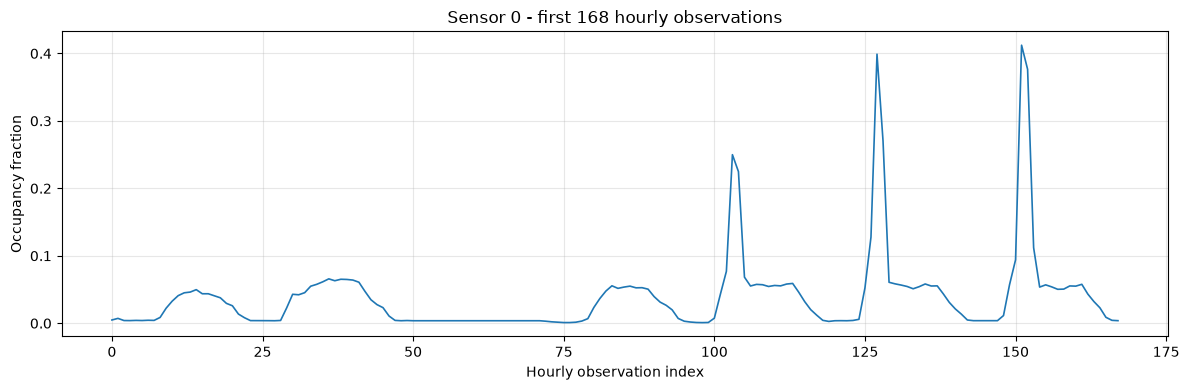

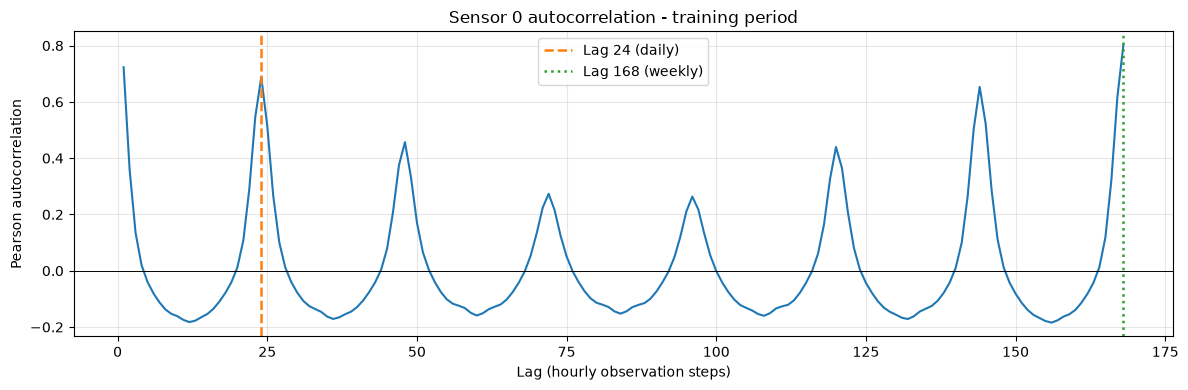

In [10]:
train_end_eda = int(0.60 * len(series_raw))
eda_train = series_raw.iloc[:train_end_eda]

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(eda_train.index, eda_train, alpha=0.4, linewidth=0.7, label="Observed occupancy")
ax.plot(eda_train.index, eda_train.rolling(24, min_periods=24).mean(),
        linewidth=1.2, label="Trailing 24-observation mean")
ax.set(title="Sensor 0 occupancy - training period",
       xlabel="Hourly observation index", ylabel="Occupancy fraction")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(eda_train.iloc[:168].index, eda_train.iloc[:168], linewidth=1.2)
ax.set(title="Sensor 0 - first 168 hourly observations",
       xlabel="Hourly observation index", ylabel="Occupancy fraction")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# shift/autocorr preserves row spacing; do not drop missing rows and compress time.
lags = np.arange(1, 169)
autocorrelations = [eda_train.autocorr(lag=int(lag)) for lag in lags]
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(lags, autocorrelations)
ax.axhline(0, color="black", linewidth=0.7)
for lag, color, style, period in [(24, "tab:orange", "--", "daily"), (168, "tab:green", ":", "weekly")]:
    ax.axvline(lag, color=color, linestyle=style, linewidth=1.8, label=f"Lag {lag} ({period})")
ax.set(title="Sensor 0 autocorrelation - training period",
       xlabel="Lag (hourly observation steps)", ylabel="Pearson autocorrelation")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## Stationarity Checks

Use sensor `0` in the **training period only**, with trailing **168-observation (weekly) mean and variance**. Stable rolling statistics support stationarity but do not prove it.

At a **5% significance level**, using constant-only tests (level stationarity):
- **ADF:** H0 = a unit root. p <= 0.05 rejects H0, supporting stationarity; p > 0.05 leaves unit-root non-stationarity unrejected.
- **KPSS:** H0 = level stationarity. p <= 0.05 rejects H0, supporting non-stationarity; p > 0.05 leaves stationarity unrejected.

Stationary does **not** mean independent or free of temporal patterns. Conflicting tests give mixed evidence, not a definitive verdict. KPSS p-values are bounded by its lookup table; boundary warnings indicate a bound rather than an exact p-value.


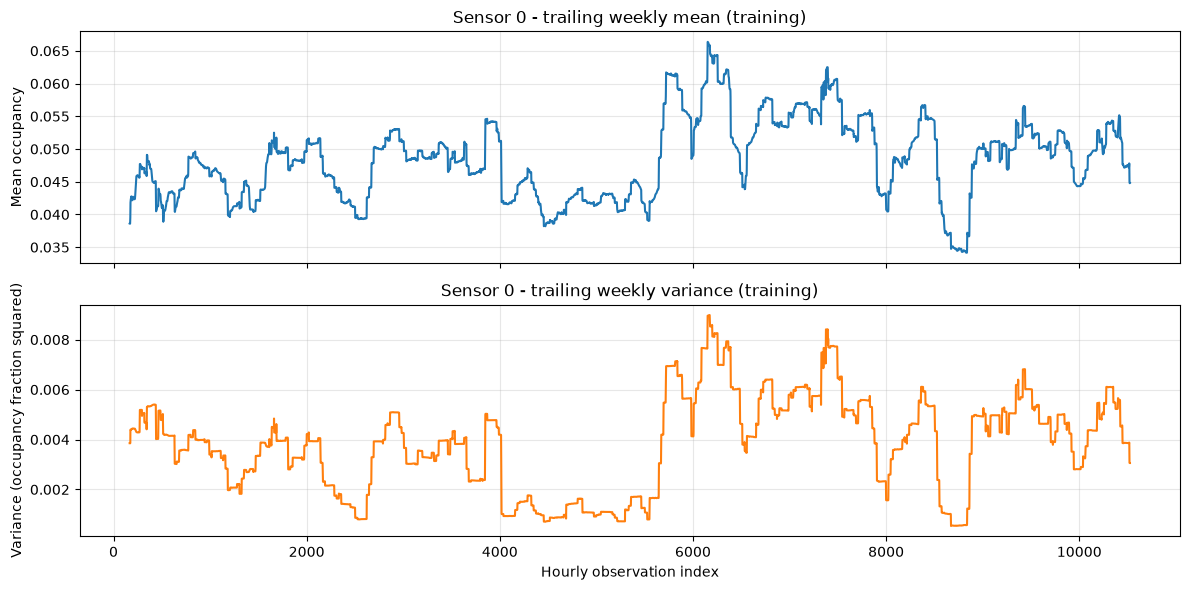

C:\Users\janik\AppData\Local\Temp\ipykernel_8024\2426374447.py:22: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(stationarity_train, regression="c", autolag="AIC")
C:\Users\janik\AppData\Local\Temp\ipykernel_8024\2426374447.py:23: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  kpss_result = kpss(stationarity_trai

,Test,Statistic,p-value,Lags,Decision (5%)
0,ADF,-12.323416,6.671661e-23,25,Reject unit root
1,KPSS,0.543017,3.197821e-02,11,Reject level stationarity


The tests give mixed evidence at 5%; stationarity remains unresolved.
Seasonality and autocorrelation can remain; no differencing is applied here.


In [11]:
from statsmodels.tsa.stattools import adfuller, kpss

ROLLING_WINDOW = 168
ALPHA = 0.05

# Use past observations only; preserve hourly spacing when filling missing inputs.
stationarity_train = series.iloc[:train_end_eda]
rolling_mean = stationarity_train.rolling(ROLLING_WINDOW).mean()
rolling_variance = stationarity_train.rolling(ROLLING_WINDOW).var()

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
axes[0].plot(rolling_mean.index, rolling_mean, color="tab:blue")
axes[0].set(title="Sensor 0 - trailing weekly mean (training)", ylabel="Mean occupancy")
axes[1].plot(rolling_variance.index, rolling_variance, color="tab:orange")
axes[1].set(title="Sensor 0 - trailing weekly variance (training)",
            xlabel="Hourly observation index", ylabel="Variance (occupancy fraction squared)")
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

adf_result = adfuller(stationarity_train, regression="c", autolag="AIC")
kpss_result = kpss(stationarity_train, regression="c", nlags="auto")
adf_p = adf_result[1]
kpss_p = kpss_result[1]

stationarity_results = pd.DataFrame([
    {"Test": "ADF", "Statistic": adf_result[0], "p-value": adf_p,
     "Lags": adf_result[2], "Decision (5%)": "Reject unit root" if adf_p <= ALPHA else "Fail to reject unit root"},
    {"Test": "KPSS", "Statistic": kpss_result[0], "p-value": kpss_p,
     "Lags": kpss_result[2], "Decision (5%)": "Reject level stationarity" if kpss_p <= ALPHA else "Fail to reject level stationarity"},
])
display(stationarity_results)

if adf_p <= ALPHA and kpss_p > ALPHA:
    stationarity_conclusion = "Both tests support level stationarity at 5%; this is evidence, not proof."
elif adf_p > ALPHA and kpss_p <= ALPHA:
    stationarity_conclusion = "Both tests support non-stationarity at 5%."
else:
    stationarity_conclusion = "The tests give mixed evidence at 5%; stationarity remains unresolved."
print(stationarity_conclusion)
print("Seasonality and autocorrelation can remain; no differencing is applied here.")


## Interpreting the Dataset

- **Stationarity:** The tests give mixed evidence at 5%; stationarity remains unresolved.
- **Trend:** a small increase in average occupancy, but no established long-term trend.
- **Seasonality:** daily (lag 24) and weekly (lag 168) repetition; weekly is stronger.
- **Cycles:** no separate longer cycle established.
- **Noise:** irregular fluctuations and spikes remain alongside seasonal patterns.
- **Lags:** correlations are about 0.72 at lag 1, 0.69 at lag 24, and 0.80 at lag 168.

These findings apply to sensor `0` in the training period. Our 24-hour lookback includes daily history but misses the weekly lag, which we can investigate later.
